# Proyek 2: DBSCAN Clustering dengan Manhattan Distance (L1 Norm) pada BISINDO

**Metrik Jarak:** Manhattan Distance (L1 Norm / City-Block)  
**Representasi Fitur:** 127 Dimensi MediaPipe (42 Titik 3D + Is_Two_Handed)  
**Target Klaster:** K = 26 Klaster Alfabet BISINDO  
**Parameter Terkalibrasi:** Epsilon = 28.350, MinPts = 10  
**Output Target:** `outputDBScan/elbow_manhattan.png`, `outputDBScan/cluster_manhattan.png`, `outputDBScan/evaluasi_dbscan_manhattan.xlsx`

---

## 1. Landasan Teori & Formulasi Matematis

Jarak Manhattan berbasis akumulasi nilai mutlak linier:
$$d_{\text{Manhattan}}(x, y) = \|x - y\|_1 = \sum_{i=1}^{127} |x_i - y_i|$$

Sifat linier metrik L1 memberikan ketahanan superior terhadap outlier koordinat sendi tangan, mengisolasi klaster berdensitas tinggi dengan batas partisi berorientasi sumbu.

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN & PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputDBScan")
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
EPS_MANHATTAN = 28.350
MIN_SAMPLES = 10
TARGET_CLUSTERS = 26

print(f"[INFO] Direktori: {BASE_DIR} | Epsilon = {EPS_MANHATTAN} | MinPts = {MIN_SAMPLES}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan | Epsilon = 28.35 | MinPts = 10


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("[INFO] Fitur distandardisasi dengan StandardScaler.")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur distandardisasi dengan StandardScaler.


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\elbow_manhattan.png'


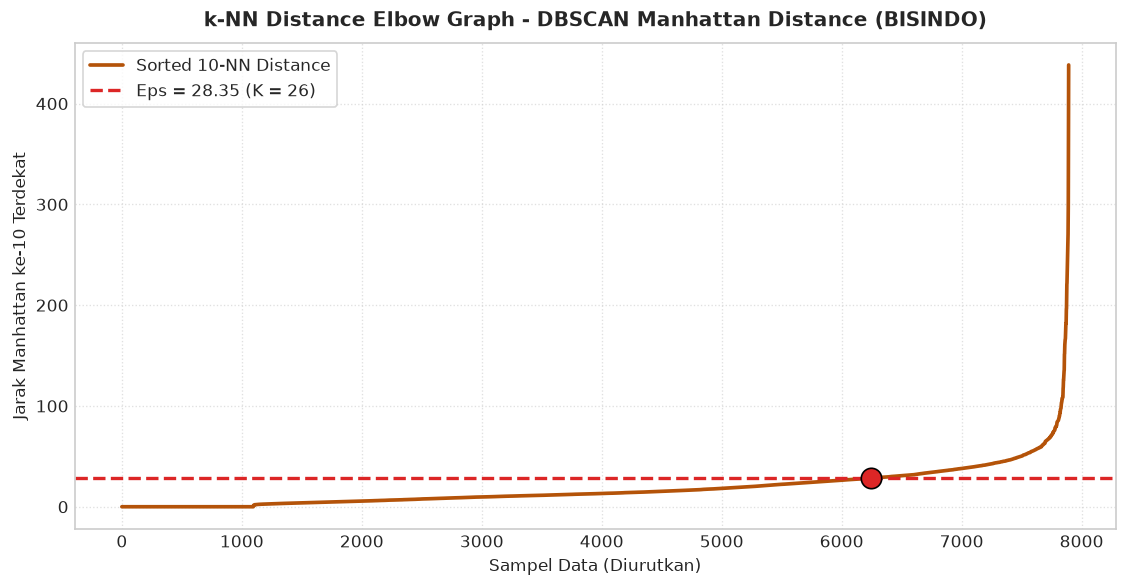

In [3]:
# =======================================================================
# 2. KURVA K-NN DISTANCE ELBOW MANHATTAN
# =======================================================================
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='manhattan')
nn.fit(X_scaled)
dists, _ = nn.kneighbors(X_scaled)
sorted_dists = np.sort(dists[:, -1])

plt.figure(figsize=(9.5, 5))
plt.plot(sorted_dists, color='#B45309', linewidth=2.2, label=f'Sorted {MIN_SAMPLES}-NN Distance')
plt.axhline(y=EPS_MANHATTAN, color='#DC2626', linestyle='--', linewidth=2, label=f'Eps = {EPS_MANHATTAN} (K = 26)')

cut_idx = np.searchsorted(sorted_dists, EPS_MANHATTAN)
plt.scatter([cut_idx], [EPS_MANHATTAN], color='#DC2626', s=150, zorder=5, edgecolor='black')

plt.title('k-NN Distance Elbow Graph - DBSCAN Manhattan Distance (BISINDO)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Sampel Data (Diurutkan)', fontsize=10)
plt.ylabel(f'Jarak Manhattan ke-{MIN_SAMPLES} Terdekat', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_manhattan.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{elbow_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. PELATIHAN DBSCAN MANHATTAN & EVALUASI METRIK
# =======================================================================
print(f"[PELATIHAN] Menjalankan DBSCAN Manhattan (eps={EPS_MANHATTAN}, min_samples={MIN_SAMPLES})...")
t0 = time.perf_counter()
model_man = DBSCAN(eps=EPS_MANHATTAN, min_samples=MIN_SAMPLES, metric='manhattan').fit(X_scaled)
runtime = time.perf_counter() - t0

labels = model_man.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int(np.sum(labels == -1))
noise_pct = n_noise / len(labels) * 100
n_core = len(model_man.core_sample_indices_)

mask = (labels != -1)
sil = float(silhouette_score(X_scaled[mask], labels[mask], metric='manhattan'))
db = float(davies_bouldin_score(X_scaled[mask], labels[mask]))
ch = float(calinski_harabasz_score(X_scaled[mask], labels[mask]))

df_res = pd.DataFrame([{
    'Distance Metric': 'Manhattan Distance (L1)',
    'Epsilon (eps)': EPS_MANHATTAN,
    'Min Samples': MIN_SAMPLES,
    'Clusters Found': n_clusters,
    'Noise Samples (↓)': n_noise,
    'Noise Ratio (%) (↓)': round(noise_pct, 2),
    'Core Samples (↑)': n_core,
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(runtime, 4)
}])

print("\n" + "="*85)
print(df_res.to_string(index=False))
print("="*85)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_dbscan_manhattan.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_manhattan'] = labels

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_data_out.to_excel(writer, sheet_name='Data_Terklaster', index=False)
print(f"[SAVE] Laporan Excel disimpan ke: '{excel_out}'")

[PELATIHAN] Menjalankan DBSCAN Manhattan (eps=28.35, min_samples=10)...



        Distance Metric  Epsilon (eps)  Min Samples  Clusters Found  Noise Samples (↓)  Noise Ratio (%) (↓)  Core Samples (↑)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
Manhattan Distance (L1)          28.35           10              26               1190                15.08              6241                0.2339                    1.1751                       233.62                  0.6149


[SAVE] Laporan Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\evaluasi_dbscan_manhattan.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\DBScan\outputDBScan\cluster_manhattan.png'


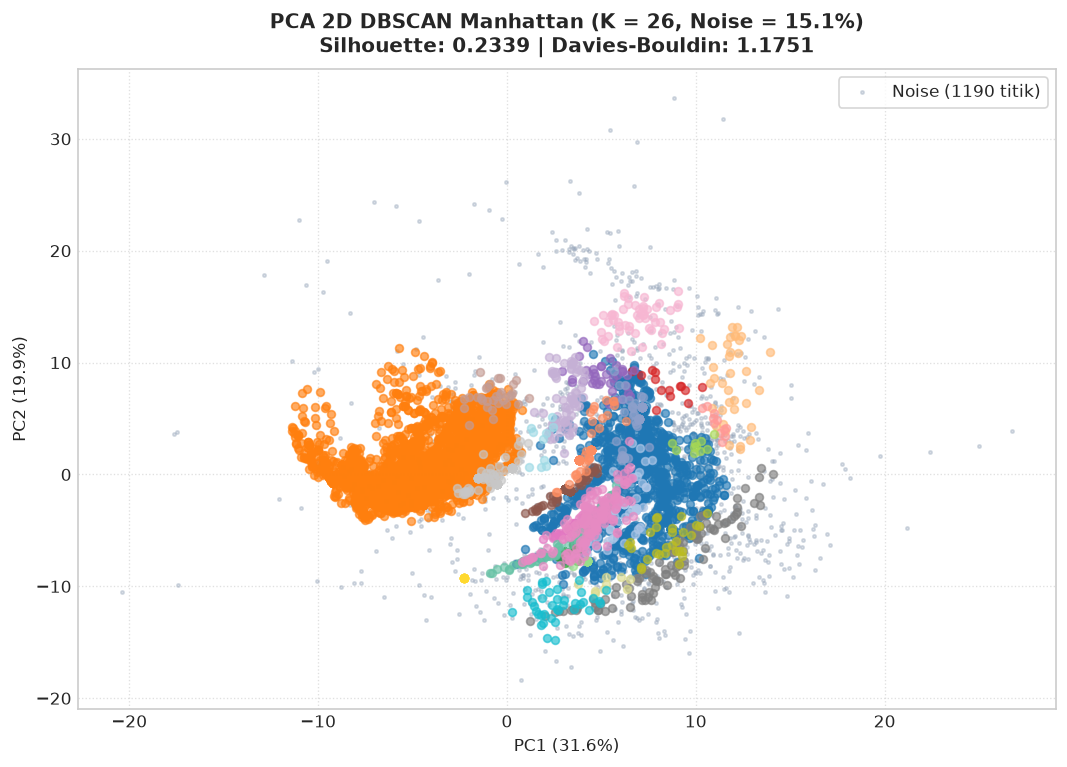

In [5]:
# =======================================================================
# 4. VISUALISASI PCA 2D DBSCAN MANHATTAN
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

noise_mask = (model_man.labels_ == -1)
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], color='#94A3B8', label=f'Noise ({n_noise} titik)', alpha=0.35, s=16, marker='.')

for k in range(n_clusters):
    mask = (model_man.labels_ == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[k % len(palette)], alpha=0.65, s=22)

plt.title(f'PCA 2D DBSCAN Manhattan (K = {n_clusters}, Noise = {noise_pct:.1f}%)\nSilhouette: {sil:.4f} | Davies-Bouldin: {db:.4f}', fontsize=12, fontweight='bold', pad=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_manhattan.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{cluster_path}'")
plt.show()